# 09 — Nature-inspired stacking

**Purpose.** Replace the stacking meta-learner of notebook 08 by a *nature-inspired optimiser* — Particle Swarm Optimisation (PSO), Grey Wolf Optimiser (GWO) and a Genetic Algorithm (GA) — that searches directly for the ensemble that maximises **macro-F1**, and test honestly whether it beats the single tuned XGBoost.

**Reads:** `../data/raw/dataset.xlsx`, `../results/tune_best_per_fold.csv`, `../results/stack_summary.csv` · **Writes:** `../results/natstack_*.csv`, `natstack_Z.npz` (cache), `natstack_convergence.png`

**Why this is feasible (the budget problem).** Tuning *model hyper-parameters* costs ~25 seconds per evaluation, so a fair budget of hundreds of evaluations per method per fold is out of reach. Optimising the **ensemble combination** is different: once the base models' out-of-fold probabilities exist, scoring one candidate ensemble takes ~0.3 milliseconds. Each optimiser can therefore afford **3,000 evaluations per fold** (about 100× the budget of notebook 07), and a fair comparison with random search is possible.

**What is being optimised (two search spaces)**

| Space | Parameters | Meaning |
|---|---|---|
| `W` | 5 | One weight per base model (normalised to sum to 1): the final probability is the weighted average of the five base models' probabilities |
| `WM` | 5 + 7 = 12 | The same weights **plus** one multiplier per disease class (0.22 – 4.5, log scale) applied before taking the arg-max — a direct shift of the decision boundaries (as in notebook 05) |

The objective is the **macro-F1 of the combined prediction on the inner out-of-fold predictions of the outer training part** — a non-differentiable metric that the logistic-regression meta-learner of notebook 08 cannot optimise directly. That is the genuine potential advantage of a metaheuristic here.

**Per outer fold (identical folds to notebooks 04–08)**
1. Base models: Logistic Regression, KNN, Random Forest (defaults), XGBoost (the setting tuned for this fold in notebook 07), HistGradientBoosting; unweighted, 14 raw features. Their 5-fold **inner** out-of-fold probabilities on the outer training part (`Z_train`) and their probabilities on the outer validation patients (`Z_val`) are computed exactly as in notebook 08 and cached on disk (the first run takes ~10–15 minutes, later runs seconds).
2. Each optimiser (and plain **random search** with the same number of evaluations as the baseline) maximises macro-F1 on `Z_train`.
3. The best candidate is applied once to `Z_val`; the outer validation patients are never used by the optimiser.

**Optimisers (all written in plain NumPy, fixed seeds, exactly 3,000 evaluations each)**
* **Random search** — 3,000 uniform random candidates. *The non-nature-inspired baseline: if an optimiser cannot beat this, its "intelligence" adds nothing.*
* **PSO** — 30 particles that move toward their own best and the swarm's best position (constriction coefficients 0.7298, c₁ = c₂ = 2.05).
* **GWO** — 30 wolves that follow the three best wolves (alpha, beta, delta) while the exploration coefficient shrinks from 2 to 0.
* **GA** — 30 individuals, tournament selection (size 3), BLX-0.3 crossover, Gaussian mutation, 2 elites carried over.

**Pre-specified decision rule.**
* Six nature-inspired candidates are compared with the reference **XGBoost (tuned)**: {PSO, GWO, GA} × {W, WM}.
* To control for testing six candidates, a candidate counts only if the **Bonferroni-adjusted** 95% paired-bootstrap interval (i.e. the 99.17% interval) of its macro-F1 gain **excludes 0** *and* it wins in **at least 4 of 5 folds**.
* If none qualifies, the single tuned XGBoost remains the final model. If one qualifies, the **calibration gate** applies before adoption: its selective accuracy at 80% coverage must be at least that of XGBoost (tuned) minus 0.01 — because notebook 12 showed that the model's confidence reliably flags its own errors, and an optimised ensemble must not destroy that.
* Random search, the logistic-regression stack and the plain average are reported as references; they do not decide anything.

**Expectation, stated in advance.** Stacking gave +0.0007 (not significant) in notebook 08 and the base models are strongly correlated, so the expected gain is at most +0.003 and no adoption. A real possibility is that the optimiser reaches a clearly higher *inner* score than random search but not a higher *outer* score (over-fitting the inner predictions); section 5 makes that visible.

**Caveats.** As in notebooks 07–08, the imputer/scaler of each outer fold saw the inner validation rows (mild inner optimism; the outer scores stay clean). Optimising 12 parameters on ~7,700 patients can over-fit; hence the inner-vs-outer comparison.

## 0. Setup

**What this does:** imports libraries and helpers, fixes the budget and prints versions.

In [1]:
import sys, os, time, json, warnings
sys.path.append('..')

import numpy as np
import pandas as pd
import sklearn, xgboost
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score
from xgboost import XGBClassifier

from src.preprocessing.cv_pipeline import preprocess_fold, load_cv_pool
from src.evaluation.metrics import (macro_f1_fast, per_class_prf, brier_multiclass, ece_top_label,
                                    mcnemar_exact, holm, bootstrap_f1_matrix)

BUDGET = 3000           # objective evaluations per optimiser per fold
POP = 30                # swarm / pack / population size
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)
print("budget per optimiser per fold:", BUDGET, "| population:", POP)
os.makedirs('../results', exist_ok=True)

pandas 3.0.5 | numpy 2.5.2 | scikit-learn 1.9.0 | xgboost 3.4.1
budget per optimiser per fold: 3000 | population: 30


## 1. Load the CV pool, the folds and the per-fold XGBoost settings

**What this does:** exactly as in notebook 08 — loads the 9,668 training patients (never the test set), verifies them against notebook 02, recreates the 5 outer folds, and reads from notebook 07 the XGBoost setting that won in each outer fold's inner search.

In [2]:
pool = load_cv_pool("../data/raw/dataset.xlsx")
assert pool.shape == (9668, 17) and pool.index.equals(pd.read_csv('../data/processed/y_train.csv', index_col=0).index)
y_global = LabelEncoder().fit_transform(pool['Disease'])
classes = sorted(pool['Disease'].unique()); K = len(classes)
AS, REA = classes.index('Ankylosing Spondylitis'), classes.index('Reactive Arthritis')

N_SPLITS = 5
folds = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42).split(pool, pool['Disease']))
cover = np.zeros(len(pool), int)
for tr, va in folds:
    cover[va] += 1
assert (cover == 1).all()

best07 = pd.read_csv('../results/tune_best_per_fold.csv')
xgb_params = {int(r['fold']): json.loads(r['best_params']) for _, r in best07[best07.model == 'XGBoost'].iterrows()}
assert sorted(xgb_params) == [1, 2, 3, 4, 5]
print("pool OK | folds:", [(len(tr), len(va)) for tr, va in folds])

pool OK | folds: [(7734, 1934), (7734, 1934), (7734, 1934), (7735, 1933), (7735, 1933)]


## 2. Base models and their out-of-fold probabilities (cached)

**What this does:** builds, for every outer fold, `Z_train` (inner 5-fold out-of-fold probabilities of the five base models on the outer training part, shape patients × 35) and `Z_val` (their probabilities on the outer validation patients). This is the same computation as notebook 08 and is the slow part (~10–15 minutes). The result is saved to `../results/natstack_Z.npz`; if that file exists the cell loads it instead (delete the file to force recomputation).

**Checks:** no missing values after preprocessing; encoded labels equal the global encoding; every 7-column block of `Z` sums to 1.

In [3]:
base = {
    'Logistic Regression':  lambda f: LogisticRegression(max_iter=2000, random_state=42),
    'KNN':                  lambda f: KNeighborsClassifier(n_neighbors=25, weights='distance', n_jobs=-1),
    'Random Forest':        lambda f: RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    'XGBoost (tuned)':      lambda f: XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=42, n_jobs=-1, **xgb_params[f]),
    'HistGradientBoosting': lambda f: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, early_stopping=False, random_state=42),
}
names = list(base); NB = len(names); XI = names.index('XGBoost (tuned)')
CACHE = '../results/natstack_Z.npz'
Z = {}
if os.path.exists(CACHE):
    zc = np.load(CACHE)
    for f in range(1, N_SPLITS + 1):
        Z[f] = (zc[f'Ztr{f}'], zc[f'Zva{f}'])
    print("loaded cached base-model predictions from", CACHE)
else:
    save = {}
    for fold, (tr, va) in enumerate(folds, 1):
        t0 = time.time()
        Xr_tr, Xr_va, _, _, y_tr, y_va = preprocess_fold(pool.iloc[tr], pool.iloc[va])
        assert Xr_tr.isna().sum().sum() == 0 and Xr_va.isna().sum().sum() == 0
        assert (y_va.to_numpy() == y_global[va]).all() and (y_tr.to_numpy() == y_global[tr]).all()
        ytr = y_tr.to_numpy()
        inner = list(StratifiedKFold(5, shuffle=True, random_state=1).split(Xr_tr, ytr))
        Ztr = np.zeros((len(ytr), K * NB)); Zva = np.zeros((len(y_va), K * NB))
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            for b, nm in enumerate(names):
                sl = slice(b * K, (b + 1) * K)
                for itr, iva in inner:
                    m = base[nm](fold).fit(Xr_tr.iloc[itr], ytr[itr]); assert list(m.classes_) == list(range(K))
                    Ztr[iva, sl] = m.predict_proba(Xr_tr.iloc[iva])
                m = base[nm](fold).fit(Xr_tr, ytr); assert list(m.classes_) == list(range(K))
                Zva[:, sl] = m.predict_proba(Xr_va)
        save[f'Ztr{fold}'], save[f'Zva{fold}'] = Ztr, Zva; Z[fold] = (Ztr, Zva)
        print(f"fold {fold}/{N_SPLITS}: base models done in {time.time() - t0:.0f}s")
    np.savez_compressed(CACHE, **save)
    print("saved", CACHE)
for f, (Ztr, Zva) in Z.items():
    for A in (Ztr, Zva):
        assert np.allclose(A.reshape(len(A), NB, K).sum(2), 1.0, atol=1e-5)
print("probability blocks valid")

fold 1/5: base models done in 50s
fold 2/5: base models done in 40s
fold 3/5: base models done in 50s
fold 4/5: base models done in 57s
fold 5/5: base models done in 44s
saved ../results/natstack_Z.npz
probability blocks valid


## 3. The ensemble objective and the three optimisers

**3a — Decoding a candidate.** A candidate is a vector `x` in [0, 1]. Its first 5 numbers become the model weights (divided by their sum, so they add to 1); in the `WM` space the next 7 become class multipliers `exp((x − 0.5) · 2 · 1.5)` (range 0.22 to 4.5, 1.0 at x = 0.5). The ensemble's class scores are the weighted average of the base probabilities times the multipliers; the prediction is the class with the highest score.

**3b — Objective.** Macro-F1 of that prediction on the (inner out-of-fold) training predictions.

**3c — Optimisers.** Each receives the objective, the dimension, the budget and a random generator, and returns the best candidate, its objective value and the *best-so-far curve* (used for the convergence plot). Every optimiser is written to use **exactly** `BUDGET` evaluations; this is asserted.

**Self-test (runs now, on a toy problem):** each optimiser minimises a simple known function (a bowl whose optimum is at 0.7 in every coordinate); all three must get within 0.05 of the optimum and clearly beat random search on this easy problem. This checks the implementations before they touch real data.

In [4]:
LOG_R = 1.5
def decode(x, use_m):
    w = np.asarray(x[:NB], float); s = w.sum()
    w = w / s if s > 1e-12 else np.full(NB, 1.0 / NB)
    m = np.exp((np.asarray(x[NB:NB + K]) - 0.5) * 2 * LOG_R) if use_m else np.ones(K)
    return w, m

def combine(Zb, w, m):                       # Zb: patients x NB x K
    P = np.einsum('nbk,b->nk', Zb, w) * m
    return P / P.sum(1, keepdims=True)

def make_objective(Zb, y, use_m):
    cnt = {'n': 0}
    def f(x):
        cnt['n'] += 1
        w, m = decode(x, use_m)
        return macro_f1_fast(y, combine(Zb, w, m).argmax(1), K)
    f.cnt = cnt
    return f

def finish(hist_vals, best_x, best_f):
    return best_x, best_f, np.maximum.accumulate(np.array(hist_vals))

def random_search(f, dim, budget, rng):
    X = rng.random((budget, dim)); vals = [f(x) for x in X]; i = int(np.argmax(vals))
    return finish(vals, X[i], vals[i])

def pso(f, dim, budget, rng, pop=POP, chi=0.7298, c1=2.05, c2=2.05, vmax=0.25):
    T = budget // pop; assert T * pop == budget
    X = rng.random((pop, dim)); V = (rng.random((pop, dim)) - 0.5) * 0.1
    fit = np.array([f(x) for x in X]); vals = list(fit)
    pb, pbf = X.copy(), fit.copy(); g = int(np.argmax(fit)); gb, gbf = X[g].copy(), fit[g]
    for _ in range(T - 1):
        r1, r2 = rng.random((pop, dim)), rng.random((pop, dim))
        V = np.clip(chi * (V + c1 * r1 * (pb - X) + c2 * r2 * (gb - X)), -vmax, vmax)
        X = np.clip(X + V, 0, 1)
        fit = np.array([f(x) for x in X]); vals += list(fit)
        imp = fit > pbf; pb[imp], pbf[imp] = X[imp], fit[imp]
        g = int(np.argmax(pbf))
        if pbf[g] > gbf: gb, gbf = pb[g].copy(), pbf[g]
    return finish(vals, gb, gbf)

def gwo(f, dim, budget, rng, pop=POP):
    T = budget // pop; assert T * pop == budget
    X = rng.random((pop, dim)); fit = np.array([f(x) for x in X]); vals = list(fit)
    bx, bf = X[int(np.argmax(fit))].copy(), fit.max()
    for t in range(1, T):
        a = 2 - 2 * t / (T - 1)
        lead = X[np.argsort(-fit)[:3]]
        Xn = np.zeros_like(X)
        for L in lead:
            A = 2 * a * rng.random((pop, dim)) - a; Cc = 2 * rng.random((pop, dim))
            Xn += (L - A * np.abs(Cc * L - X))
        X = np.clip(Xn / 3, 0, 1)
        fit = np.array([f(x) for x in X]); vals += list(fit)
        if fit.max() > bf: bx, bf = X[int(np.argmax(fit))].copy(), fit.max()
    return finish(vals, bx, bf)

def ga(f, dim, budget, rng, pop=POP, elite=2, alpha=0.3, sigma=0.1):
    X = rng.random((pop, dim)); fit = np.array([f(x) for x in X]); vals = list(fit); used = pop
    while used < budget:
        n_new = min(pop - elite, budget - used)
        order = np.argsort(-fit); E, Ef = X[order[:elite]], fit[order[:elite]]
        def tour():
            idx = rng.integers(0, pop, 3); return X[idx[np.argmax(fit[idx])]]
        kids = np.empty((n_new, dim))
        for i in range(n_new):
            p1, p2 = tour(), tour(); lo, hi = np.minimum(p1, p2), np.maximum(p1, p2); d = hi - lo
            c = rng.uniform(lo - alpha * d, hi + alpha * d)
            mut = rng.random(dim) < 1.0 / dim
            c = c + mut * rng.normal(0, sigma, dim)
            kids[i] = np.clip(c, 0, 1)
        kf = np.array([f(k) for k in kids]); vals += list(kf); used += n_new
        X = np.vstack([E, kids]); fit = np.concatenate([Ef, kf])
        if len(X) < pop:                       # last, shorter generation: pad with the best of the previous one
            X = np.vstack([X, X[:pop - len(X)]]); fit = np.concatenate([fit, fit[:pop - len(fit)]])
    i = int(np.argmax(fit))
    return finish(vals, X[i], fit[i])

optimisers = {'RS': random_search, 'PSO': pso, 'GWO': gwo, 'GA': ga}

# ---- self-test on a toy problem: maximise -(sum (x-0.7)^2)
class _Toy:
    def __init__(self): self.n = 0
    def __call__(self, x): self.n += 1; return -float(((x - 0.7) ** 2).sum())
res = {}
for nm, opt in optimisers.items():
    toy = _Toy(); bx, bf, h = opt(toy, 12, 3000, np.random.default_rng(0))
    assert toy.n == 3000 and len(h) == 3000, (nm, toy.n, len(h))
    res[nm] = (np.abs(bx - 0.7).max(), bf)
    print(f"{nm:<4} evaluations used={toy.n}  max distance to optimum={res[nm][0]:.3f}  best value={bf:.5f}")
for nm in ('PSO', 'GWO', 'GA'):
    assert res[nm][0] < 0.05 and res[nm][1] > res['RS'][1], f"{nm} failed the self-test"
print("optimiser self-test passed")

RS   evaluations used=3000  max distance to optimum=0.337  best value=-0.25394
PSO  evaluations used=3000  max distance to optimum=0.000  best value=-0.00000
GWO  evaluations used=3000  max distance to optimum=0.006  best value=-0.00016
GA   evaluations used=3000  max distance to optimum=0.002  best value=-0.00002
optimiser self-test passed


## 4. Run everything: optimise on the training predictions, score on the validation patients

**What this does, for each outer fold**
1. Builds the 3-D array of base probabilities (patients × 5 models × 7 classes).
2. For each of the 4 optimisers × 2 spaces (8 runs) maximises macro-F1 on `Z_train`, using exactly 3,000 evaluations (checked), with a seed that depends only on fold, method and space (reproducible).
3. Applies the best candidate to `Z_val` and records the outer macro-F1 plus the *inner* objective that was achieved (for the over-fitting check).
4. Also scores the references: each base model alone, the plain average of all five (`avg_all`), and the logistic-regression stack of notebook 08 (`stack_lr`, re-trained here so it can be paired with the new candidates).

**Runtime:** about 1–3 minutes in total (the base-model work is cached).

In [5]:
spaces = {'W': False, 'WM': True}
dims = {'W': NB, 'WM': NB + K}
configs = names + ['avg_all', 'stack_lr'] + [f"{o}_{s}" for o in optimisers for s in spaces]
oof = {c: np.zeros((len(pool), K)) for c in configs}
fold_rows, opt_rows, curves = [], [], {}
y_all = np.full(len(pool), -1)

def record(fold, cfg, P, yva):
    pred = P.argmax(1); pr, rc, f1 = per_class_prf(yva, pred, K)
    fold_rows.append({'fold': fold, 'config': cfg, 'macro_f1': f1_score(yva, pred, average='macro'),
                      'balanced_accuracy': rc.mean(), 'AS_f1': f1[AS], 'ReA_f1': f1[REA]})

for fold, (tr, va) in enumerate(folds, 1):
    Ztr, Zva = Z[fold]
    ytr, yva = y_global[tr], y_global[va]
    y_all[va] = yva
    Zb_tr, Zb_va = Ztr.reshape(len(Ztr), NB, K), Zva.reshape(len(Zva), NB, K)
    for b, nm in enumerate(names):
        oof[nm][va] = Zb_va[:, b, :]; record(fold, nm, Zb_va[:, b, :], yva)
    P = Zb_va.mean(1); oof['avg_all'][va] = P; record(fold, 'avg_all', P, yva)
    meta = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10, 100], cv=StratifiedKFold(5, shuffle=True, random_state=0),
                                scoring='f1_macro', max_iter=3000, random_state=0, n_jobs=-1)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore'); meta.fit(Ztr, ytr)
    P = meta.predict_proba(Zva); oof['stack_lr'][va] = P; record(fold, 'stack_lr', P, yva)
    t0 = time.time()
    for oi, (oname, opt) in enumerate(optimisers.items()):
        for si, (sname, use_m) in enumerate(spaces.items()):
            f = make_objective(Zb_tr, ytr, use_m)
            rng = np.random.default_rng(1000 * fold + 10 * oi + si)
            bx, bf, hist = opt(f, dims[sname], BUDGET, rng)
            assert f.cnt['n'] == BUDGET and len(hist) == BUDGET
            w, m = decode(bx, use_m)
            P = combine(Zb_va, w, m); cfg = f"{oname}_{sname}"
            oof[cfg][va] = P; record(fold, cfg, P, yva)
            curves.setdefault(cfg, []).append(hist)
            opt_rows.append({'fold': fold, 'method': oname, 'space': sname, 'inner_best': bf,
                             'outer_macro_f1': macro_f1_fast(yva, P.argmax(1), K),
                             'w': json.dumps([round(float(v), 4) for v in w]), 'm': json.dumps([round(float(v), 4) for v in m])})
    print(f"fold {fold}/{N_SPLITS}: 8 optimiser runs in {time.time() - t0:.0f}s (budget {BUDGET} each)")

fold_df = pd.DataFrame(fold_rows); opt_df = pd.DataFrame(opt_rows)
oof_pred = {k: v.argmax(1) for k, v in oof.items()}
assert (y_all == y_global).all()
for k, Pm in oof.items():
    assert np.allclose(Pm.sum(1), 1.0, atol=1e-6), k
print("done; all out-of-fold probability rows valid")

fold 1/5: 8 optimiser runs in 22s (budget 3000 each)
fold 2/5: 8 optimiser runs in 21s (budget 3000 each)
fold 3/5: 8 optimiser runs in 20s (budget 3000 each)
fold 4/5: 8 optimiser runs in 19s (budget 3000 each)
fold 5/5: 8 optimiser runs in 18s (budget 3000 each)
done; all out-of-fold probability rows valid


## 5. Reproduction check and the over-fitting check

**5a — Reproduction of notebook 08.** The base models' standalone scores and the `stack_lr` score must equal the values stored by notebook 08 (`stack_summary.csv`): same folds, same models, same settings. **If any difference exceeds 0.0005, stop and investigate.**

**5b — How well do the optimisers optimise, and does it generalise?** For each method and space: the mean *inner* objective (the macro-F1 the optimiser achieved on the training predictions it saw), the mean *outer* macro-F1 (on unseen patients), and their gap. The optimisers are compared on the inner column (who finds the better solution?); generalisation is the outer column. A large gap means the optimiser fits noise in its own training predictions.

In [6]:
s08 = pd.read_csv('../results/stack_summary.csv').set_index('config')['macro_f1_mean']
gmean = fold_df.groupby('config').macro_f1.mean()
chk = pd.DataFrame({'notebook_08': s08.reindex(names + ['avg_all', 'stack_lr']),
                    'this_notebook': gmean.reindex(names + ['avg_all', 'stack_lr'])})
chk['diff'] = chk['this_notebook'] - chk['notebook_08']
print(chk.round(5).to_string())
print("\nmax |diff| =", chk['diff'].abs().max().round(6))
if chk['diff'].abs().max() > 0.0005:
    print("WARNING: does not reproduce notebook 08 - investigate before trusting anything below.")

g = opt_df.groupby(['method', 'space'])[['inner_best', 'outer_macro_f1']].mean()
g['gap (inner - outer)'] = g['inner_best'] - g['outer_macro_f1']
print("\nInner objective achieved vs outer macro-F1 (mean over 5 folds):")
print(g.round(4).to_string())

                      notebook_08  this_notebook  diff
config                                                
Logistic Regression       0.78888        0.78888   0.0
KNN                       0.70581        0.70581   0.0
Random Forest             0.82303        0.82303   0.0
XGBoost (tuned)           0.82544        0.82544   0.0
HistGradientBoosting      0.81251        0.81251   0.0
avg_all                   0.82590        0.82590   0.0
stack_lr                  0.82605        0.82605   0.0

max |diff| = 0.0

Inner objective achieved vs outer macro-F1 (mean over 5 folds):
              inner_best  outer_macro_f1  gap (inner - outer)
method space                                                 
GA     W          0.8301          0.8280               0.0021
       WM         0.8303          0.8204               0.0098
GWO    W          0.8305          0.8283               0.0022
       WM         0.8319          0.8247               0.0072
PSO    W          0.8303          0.8260          

## 6. Results table

**What this does:** one row per configuration, sorted by mean fold macro-F1: 5-fold mean ± std, pooled out-of-fold score with a 95% bootstrap interval (5,000 resamples), the two problem classes, calibration (Brier, ECE) and **selective accuracy** — the accuracy on the 80% / 70% of patients the ensemble is most confident about (the deferral view of notebook 12). A configuration that wins on macro-F1 but loses selective accuracy is spending the model's most valuable property.

In [7]:
keys_b, F = bootstrap_f1_matrix(y_all, oof_pred, B=5000, seed=42)
kpos = {k: j for j, k in enumerate(keys_b)}
def sel_acc(P, y, cov):
    keep = np.argsort(-P.max(1))[:int(round(cov * len(y)))]
    return float((P.argmax(1)[keep] == y[keep]).mean())
gk = fold_df.groupby('config')
rows_s = []
for k in configs:
    pr, rc, f1 = per_class_prf(y_all, oof_pred[k], K)
    rows_s.append({'config': k, 'macro_f1_mean': gk.macro_f1.mean()[k], 'macro_f1_std': gk.macro_f1.std()[k],
                   'oof_macro_f1': macro_f1_fast(y_all, oof_pred[k], K),
                   'ci_low': np.percentile(F[:, kpos[k]], 2.5), 'ci_high': np.percentile(F[:, kpos[k]], 97.5),
                   'AS_f1': f1[AS], 'ReA_f1': f1[REA], 'brier': brier_multiclass(y_all, oof[k]), 'ece': ece_top_label(y_all, oof[k]),
                   'acc@80%cov': sel_acc(oof[k], y_all, 0.8), 'acc@70%cov': sel_acc(oof[k], y_all, 0.7)})
summary = pd.DataFrame(rows_s).sort_values('macro_f1_mean', ascending=False).reset_index(drop=True)
summary.round(4)

,config,macro_f1_mean,macro_f1_std,oof_macro_f1,ci_low,ci_high,AS_f1,ReA_f1,brier,ece,acc@80%cov,acc@70%cov
0,RS_W,0.8284,0.0052,0.8284,0.8197,0.8366,0.6738,0.6694,0.2133,0.0316,0.9117,0.9481
1,GWO_W,0.8283,0.0052,0.8283,0.8197,0.8366,0.6732,0.6741,0.2137,0.0309,0.9103,0.9465
2,GA_W,0.8280,0.0054,0.8280,0.8195,0.8364,0.6739,0.6695,0.2134,0.0328,0.9123,0.9470
3,stack_lr,0.8260,0.0051,0.8261,0.8176,0.8344,0.6706,0.6685,0.2156,0.0382,0.9139,0.9512
4,PSO_W,0.8260,0.0064,0.8261,0.8175,0.8344,0.6681,0.6722,0.2125,0.0257,0.9110,0.9484
5,avg_all,0.8259,0.0056,0.8259,0.8172,0.8345,0.6709,0.6600,0.2194,0.0360,0.9070,0.9406
6,XGBoost (tuned),0.8254,0.0078,0.8254,0.8166,0.8337,0.6671,0.6703,0.2098,0.0153,0.9113,0.9484
7,PSO_WM,0.8247,0.0060,0.8248,0.8163,0.8332,0.6705,0.6649,0.2187,0.0297,0.9092,0.9422
8,GWO_WM,0.8247,0.0062,0.8248,0.8163,0.8333,0.6710,0.6667,0.2145,0.0270,0.9116,0.9480
9,RS_WM,0.8231,0.0061,0.8232,0.8148,0.8316,0.6749,0.6667,0.2205,0.0287,0.9091,0.9422


## 7. What did the optimisers choose?

**What this does:** the mean weight each optimiser gives to each base model (rows sum to 1) and, for the `WM` space, the mean class multipliers (> 1 boosts a class, < 1 suppresses it), averaged over the 5 folds. If all optimisers put most weight on XGBoost and keep multipliers near 1, they have rediscovered "just use XGBoost" — which is the honest explanation of a null result.

In [8]:
wts = {}
for (meth, sp), grp in opt_df.groupby(['method', 'space']):
    wts[f"{meth}_{sp}"] = np.mean([json.loads(s) for s in grp['w']], axis=0)
print("Mean model weights:")
print(pd.DataFrame(wts, index=names).T.round(3).to_string())
mult = {f"{meth}_WM": np.mean([json.loads(s) for s in grp['m']], axis=0)
        for (meth, sp), grp in opt_df.groupby(['method', 'space']) if sp == 'WM'}
print("\nMean class multipliers (WM space):")
print(pd.DataFrame(mult, index=classes).T.round(2).to_string())

Mean model weights:
        Logistic Regression    KNN  Random Forest  XGBoost (tuned)  HistGradientBoosting
GA_W                  0.188  0.036          0.365            0.354                 0.056
GA_WM                 0.239  0.116          0.208            0.272                 0.165
GWO_W                 0.200  0.006          0.422            0.328                 0.044
GWO_WM                0.195  0.008          0.241            0.491                 0.065
PSO_W                 0.144  0.003          0.418            0.364                 0.071
PSO_WM                0.284  0.036          0.319            0.253                 0.107
RS_W                  0.205  0.019          0.367            0.374                 0.035
RS_WM                 0.163  0.078          0.308            0.345                 0.106

Mean class multipliers (WM space):
        Ankylosing Spondylitis  Normal  Psoriatic Arthritis  Reactive Arthritis  Rheumatoid Arthritis  Sjögren's Syndrome  Systemic Lupus Eryth

## 8. Convergence plot

**What this does:** the best objective found so far against the number of evaluations, averaged over the 5 folds, for the 12-parameter space (log-scale x-axis). It shows how quickly each optimiser improves and whether any separates from random search. Saved to `../results/natstack_convergence.png`.

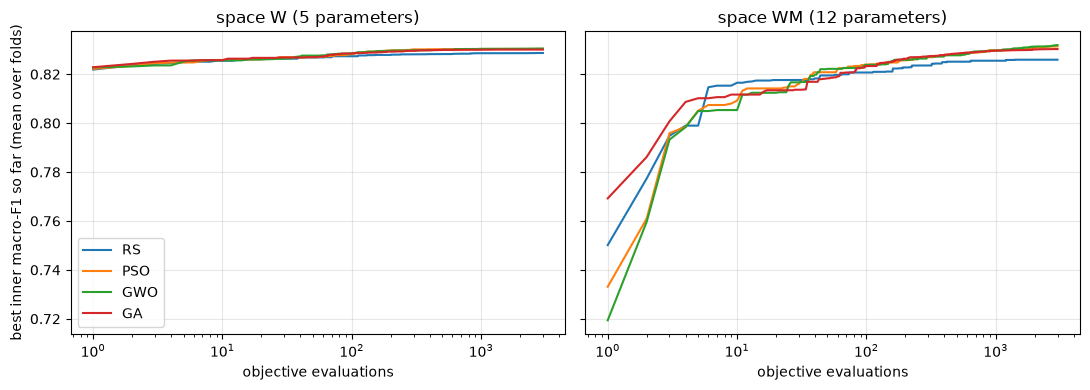

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, sp in zip(ax, ('W', 'WM')):
    for o in optimisers:
        h = np.mean(curves[f"{o}_{sp}"], axis=0)
        a.plot(np.arange(1, BUDGET + 1), h, label=o)
    a.set_xscale('log'); a.set_title(f"space {sp} ({dims[sp]} parameters)"); a.set_xlabel('objective evaluations'); a.grid(alpha=0.3)
ax[0].set_ylabel('best inner macro-F1 so far (mean over folds)'); ax[0].legend()
plt.tight_layout(); plt.savefig('../results/natstack_convergence.png', dpi=150); plt.show()

## 9. The pre-specified decision

**What this does:** compares each of the six nature-inspired candidates (PSO, GWO, GA × W, WM) with the reference XGBoost (tuned) on the same patients.

* `diff`: pooled out-of-fold macro-F1 difference (candidate − XGBoost); `ci95_low`/`ci95_high`: the ordinary 95% paired-bootstrap interval; `ci_adj_low`: the lower end of the **Bonferroni-adjusted** interval (99.17%) that the rule uses;
* `folds_better`: folds (of 5) where the candidate beats XGBoost;
* McNemar b/c and the Holm-corrected p (accuracy view; informational).

A candidate **qualifies** if `ci_adj_low > 0` and `folds_better ≥ 4`. The informational block underneath compares each optimiser with **random search in the same space** (does the nature-inspired part add anything?) and the logistic-regression stack.

In [10]:
ref = 'XGBoost (tuned)'
piv = fold_df.pivot(index='fold', columns='config', values='macro_f1')
cands = [f"{o}_{s}" for o in ('PSO', 'GWO', 'GA') for s in spaces]
alpha_adj = 0.05 / len(cands)
def cmp(A, B):
    d = F[:, kpos[A]] - F[:, kpos[B]]
    b, c, p = mcnemar_exact(y_all, oof_pred[A], oof_pred[B]); fd = piv[A] - piv[B]
    return {'A': A, 'B': B, 'diff': macro_f1_fast(y_all, oof_pred[A], K) - macro_f1_fast(y_all, oof_pred[B], K),
            'ci95_low': np.percentile(d, 2.5), 'ci95_high': np.percentile(d, 97.5),
            'ci_adj_low': np.percentile(d, 100 * alpha_adj / 2), 'folds_better': int((fd > 0).sum()),
            'mcnemar_b': b, 'mcnemar_c': c, 'p_raw': p}
dec = pd.DataFrame([cmp(c, ref) for c in cands])
dec['p_holm'] = holm(dec['p_raw'])
dec['qualifies'] = (dec['ci_adj_low'] > 0) & (dec['folds_better'] >= 4)
print("Nature-inspired candidates vs XGBoost (tuned):")
print(dec.drop(columns=['B', 'p_raw']).rename(columns={'A': 'candidate'}).round(4).to_string(index=False))

info = [cmp(f"{o}_{s}", f"RS_{s}") for o in ('PSO', 'GWO', 'GA') for s in spaces] + [cmp('stack_lr', ref), cmp('avg_all', ref)]
info = pd.DataFrame(info)
print("\nInformational: optimisers vs random search (same space), and the notebook-08 references vs XGBoost:")
print(info.drop(columns=['p_raw']).rename(columns={'A': 'A', 'B': 'B'}).round(4).to_string(index=False))

q = dec[dec.qualifies]
if len(q) == 0:
    decision = "No nature-inspired stack qualifies -> FINAL MODEL stays XGBoost (tuned) alone"
else:
    best = q.sort_values('diff', ascending=False).iloc[0]['A']
    s_best = summary.set_index('config').loc[best]; s_ref = summary.set_index('config').loc[ref]
    gate = s_best['acc@80%cov'] >= s_ref['acc@80%cov'] - 0.01
    decision = (f"{best} qualifies on macro-F1; calibration gate (selective accuracy @80% {s_best['acc@80%cov']:.4f} vs "
                f"XGBoost {s_ref['acc@80%cov']:.4f}): {'PASSED -> adopt' if gate else 'FAILED -> keep XGBoost (tuned) alone'}")
print("\nDECISION:", decision)

Nature-inspired candidates vs XGBoost (tuned):
candidate    diff  ci95_low  ci95_high  ci_adj_low  folds_better  mcnemar_b  mcnemar_c  p_holm  qualifies
    PSO_W  0.0007   -0.0029     0.0043     -0.0042             4        137        142  1.0000      False
   PSO_WM -0.0006   -0.0049     0.0037     -0.0065             1        194        204  1.0000      False
    GWO_W  0.0029   -0.0008     0.0066     -0.0022             4        161        143  1.0000      False
   GWO_WM -0.0006   -0.0045     0.0034     -0.0059             1        166        187  1.0000      False
     GA_W  0.0026   -0.0011     0.0064     -0.0024             4        163        142  1.0000      False
    GA_WM -0.0048   -0.0091    -0.0003     -0.0104             0        190        227  0.4667      False

Informational: optimisers vs random search (same space), and the notebook-08 references vs XGBoost:
       A               B    diff  ci95_low  ci95_high  ci_adj_low  folds_better  mcnemar_b  mcnemar_c
   PSO_W

## 10. Save the results

**What this does:** writes all tables to `../results/`. The base-model cache `natstack_Z.npz` is also kept so that notebook 10 can reuse the exact same predictions if a stack is ever adopted.

In [11]:
fold_df.to_csv('../results/natstack_fold_scores.csv', index=False)
summary.to_csv('../results/natstack_summary.csv', index=False)
opt_df.to_csv('../results/natstack_optimiser_runs.csv', index=False)
dec.drop(columns=['p_raw']).to_csv('../results/natstack_decision.csv', index=False)
info.drop(columns=['p_raw']).to_csv('../results/natstack_informational.csv', index=False)
np.savez_compressed('../results/natstack_oof.npz', y=y_all, classes=np.array(classes),
                    **{k.replace(' ', '_').replace('(', '').replace(')', ''): v.astype(np.float32) for k, v in oof.items()})
print(sorted(f for f in os.listdir('../results') if f.startswith('natstack')))
print("\nDECISION:", decision)

['natstack_Z.npz', 'natstack_convergence.png', 'natstack_decision.csv', 'natstack_fold_scores.csv', 'natstack_informational.csv', 'natstack_oof.npz', 'natstack_optimiser_runs.csv', 'natstack_summary.csv']

DECISION: No nature-inspired stack qualifies -> FINAL MODEL stays XGBoost (tuned) alone


## Summary — what this notebook establishes

* Whether directly optimising macro-F1 with nature-inspired search (PSO, GWO, GA) over ensemble weights and class multipliers beats the tuned XGBoost by more than noise, with family-wise error control across the six candidates.
* Whether the nature-inspired part adds anything over random search with the same budget (section 5b and the informational block of section 9).
* Whether any gain would survive the calibration gate that protects the deferral property found in notebook 12.
* Either way, the paper can report a properly controlled nature-inspired experiment — a positive or a negative result.